In [1]:
from typing import TypedDict, Optional, Dict, Any
from langchain_ollama import ChatOllama
from langchain_experimental.tools import PythonREPLTool
from langchain_core.prompts import PromptTemplate
from langgraph.types import interrupt, Command
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# 1. State Schema (Carried over from Notebook 01)
class DataScienceState(TypedDict):
    dataset_path: str
    dataset_summary: Optional[str]
    missing_values_summary: Optional[str]
    requires_imputation: bool
    imputation_strategy: Optional[str]
    scaling_strategy: Optional[str]
    hyperparameters: Optional[Dict[str, Any]]

# 2. Initialize LLM and REPL
llm = ChatOllama(model="qwen2.5-coder:3b", temperature=0)
python_repl = PythonREPLTool()

def extract_code_block(llm_response: str) -> str:
    if "```python" in llm_response:
        return llm_response.split("```python")[1].split("```")[0].strip()
    elif "```" in llm_response:
        return llm_response.split("```")[1].split("```")[0].strip()
    return llm_response.replace("Action: python_repl_ast", "").replace("Action Input:", "").strip()

print("Environment initialized for HITL Preprocessing.")

C:\Users\Shivachetan Ulavi\AppData\Local\Temp\ipykernel_17164\1322405924.py:3: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.tools import PythonREPLTool


Environment initialized for HITL Preprocessing.


In [2]:
def ask_imputation_node(state: DataScienceState) -> DataScienceState:
    print("--PAUSED: ASK IMPUTATION--")
    if state.get("requires_imputation"):
        human_choice = interrupt({
            "question" : "Missing values detected. Select Imputation Strategy:",
            "options" : ["KNN", "Mean", "Median", "Drop"],
            "context" : state["missing_values_summary"]
        })
        print(f"Human Selected: {human_choice}")
        return {"imputation_strategy": human_choice}
    else:
        print("No imputation required. Skipping.")
        return {"imputation_strategy": "None"}

def ask_scaling_node(state: DataScienceState) -> DataScienceState:
    print("----PAUSED: ASK SCALING----")
    human_choice = interrupt({
        "question" : "Select feature scaling strategy(recommended for Neural Nets):",
        "options" : ["StandardScaler", "MinMaxScaler", "None"]
    })

    print(f"Human selected:{human_choice}")
    return {"scaling_strategy": human_choice}

print("HITL Nodes Defined")

HITL Nodes Defined


In [3]:
def preprocessing_node(state: DataScienceState) -> DataScienceState:
    print("--Entering Preprocessing node")

    preprocess_prompt = PromptTemplate.from_template(
        """
        You are a data engineer. A dataset is at '{filepath}'.
        The user has requested the following preprocessing steps:
        - Imputation Strategy: {imputation}
        - Scaling Strategy: {scaling}
        
        Write a single block of Python code using pandas and scikit-learn to:
        1. Load the dataset.
        2. If Imputation is not 'None', apply the requested imputation to numerical columns.
        3. If Scaling is not 'None', apply the requested scaling to numerical columns.
        4. Save the transformed dataframe to '../data/processed_dataset.csv' without the index.
        
        CRITICAL INSTRUCTION:
        Return ONLY valid Python code inside a ```python ``` markdown block. Do not explain.
        """
    )

    chain = preprocess_prompt | llm
    response = chain.invoke({
        "filepath" : state["dataset_path"],
        "imputation": state["imputation_strategy"],
        "scaling" : state["scaling_strategy"]
    })

    executable_code = extract_code_block(response.content)
    print("Generated Preprocessing Code:\n", executable_code)
    
    print("\nExecuting Preprocessing via REPL...")
    repl_output = python_repl.invoke(executable_code)
    print("REPL Output:", repl_output)
    
    # Update the state to point to the new clean dataset for the PyTorch node
    return {"dataset_path": "../data/processed_dataset.csv"}

print("Preprocessing Node defined.")

Preprocessing Node defined.


Building a graph

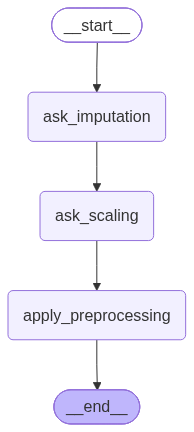

In [4]:
builder = StateGraph(DataScienceState)
builder.add_node("ask_imputation", ask_imputation_node)
builder.add_node("ask_scaling", ask_scaling_node)
builder.add_node("apply_preprocessing", preprocessing_node)

builder.add_edge(START, "ask_imputation")
builder.add_edge("ask_imputation", "ask_scaling")
builder.add_edge("ask_scaling", "apply_preprocessing")
builder.add_edge("apply_preprocessing", END)

#compile with checkpointer(important for Human in the loop)
memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [5]:
# Thread config is required for the checkpointer to track the state history
config = {"configurable": {"thread_id": "test_run_diabetes_01"}}

# Initial state using the new Diabetes dataset
initial_state = {
    "dataset_path": "../data/Diabetes_Missing_Data.csv",
    "requires_imputation": True, 
    "missing_values_summary": "Glucose: 5, Diastolic_BP: 35, Skin_Fold: 227, Serum_Insulin: 374, BMI: 11"
}

print("=== STARTING GRAPH EXECUTION ===")
# 1. Start the graph. It will pause at ask_imputation_node.
for event in graph.stream(initial_state, config=config):
    print(event)

# 2. Simulate User Input: Resuming from Imputation Pause
print("\n=== RESUMING GRAPH: SUBMITTING IMPUTATION ===")
# Let's use Median imputation since Serum_Insulin has a lot of missing values
for event in graph.stream(Command(resume="Median"), config=config):
    print(event)

# 3. Simulate User Input: Resuming from Scaling Pause
print("\n=== RESUMING GRAPH: SUBMITTING SCALING ===")
# Standard scaling is great for PyTorch neural nets
for event in graph.stream(Command(resume="StandardScaler"), config=config):
    print(event)

=== STARTING GRAPH EXECUTION ===
--PAUSED: ASK IMPUTATION--
{'__interrupt__': (Interrupt(value={'question': 'Missing values detected. Select Imputation Strategy:', 'options': ['KNN', 'Mean', 'Median', 'Drop'], 'context': 'Glucose: 5, Diastolic_BP: 35, Skin_Fold: 227, Serum_Insulin: 374, BMI: 11'}, id='8467deef34c623a6c990c10da1f2737b'),)}

=== RESUMING GRAPH: SUBMITTING IMPUTATION ===
--PAUSED: ASK IMPUTATION--
Human Selected: Median
{'ask_imputation': {'imputation_strategy': 'Median'}}
----PAUSED: ASK SCALING----
{'__interrupt__': (Interrupt(value={'question': 'Select feature scaling strategy(recommended for Neural Nets):', 'options': ['StandardScaler', 'MinMaxScaler', 'None']}, id='9353608ae2b0e1c6886a212aef9a66fd'),)}

=== RESUMING GRAPH: SUBMITTING SCALING ===
----PAUSED: ASK SCALING----
Human selected:StandardScaler
{'ask_scaling': {'scaling_strategy': 'StandardScaler'}}
--Entering Preprocessing node


Python REPL can execute arbitrary code. Use with caution.


Generated Preprocessing Code:
 import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = pd.read_csv('../data/Diabetes_Missing_Data.csv')

# Define the imputation and scaling strategies
imputation_strategy = 'median'
scaling_strategy = 'standard'

# Impute missing values if requested
if imputation_strategy != 'None':
    imputer = SimpleImputer(strategy=imputation_strategy)
    data_imputed = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)

# Scale the data if requested
if scaling_strategy != 'None':
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_imputed)
    data_scaled = pd.DataFrame(data_scaled, columns=data_imputed.columns)

# Save the transformed dataframe to a CSV file
data_scaled.to_csv('../data/processed_dataset.csv', index=False)

Executing Preprocessing via REPL...
REPL Output: 
{'apply_preprocessing': {'dataset_path': '../data/processed_dataset.csv'}}


Now completing the graph using the eda_node from notebook 01, but changing requires_imputation by parsing the exact flag printed by pandas!

In [6]:
def eda_node(state: DataScienceState) -> DataScienceState:
    print("--Entering EDA Node--")
    dataset_path = state["dataset_path"]

    # Updated prompt forces pandas to evaluate the missing values boolean
    eda_prompt = PromptTemplate.from_template("""
        You are a senior data scientist. A dataset is located at '{filepath}'.
        Write a single block of Python code using pandas to do the following:
        1. Load the dataset.
        2. Print the dataframe info.
        3. Print the missing values sum for each column.
        4. Print exactly 'REQUIRES_IMPUTATION: True' if there are ANY missing values in the dataframe, otherwise print 'REQUIRES_IMPUTATION: False'.
        5. Save a matplotlib distribution plot of the numerical columns to '../data/plots/eda_distributions.png'.
        
        CRITICAL INSTRUCTION:
        Return ONLY valid Python code inside a ```python ``` markdown block. 
        Do not explain the code. Do not use 'Action Input'. Just write the code.
        """)

    # Invoke LLM and extract code
    chain = eda_prompt | llm
    response = chain.invoke({"filepath": dataset_path})
    executable_code = extract_code_block(response.content)

    # Execute the code safely using REPL tool
    print("\n Executing code via REPL...")
    repl_output = python_repl.invoke(executable_code)

    # Robust parsing: we look for the exact flag printed by pandas
    requires_imputation = "REQUIRES_IMPUTATION: True" in repl_output

    return {
        "dataset_summary": repl_output,
        "missing_values_summary": repl_output,
        "requires_imputation": requires_imputation
    }

print("EDA Node defined.")

EDA Node defined.


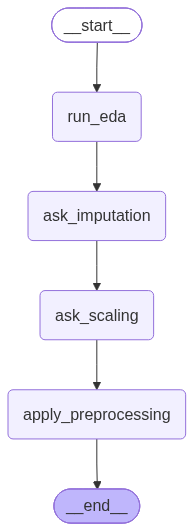

In [7]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

# 1. Build the Full Graph (incorporating the eda_node)
builder = StateGraph(DataScienceState)
builder.add_node("run_eda", eda_node)
builder.add_node("ask_imputation", ask_imputation_node)
builder.add_node("ask_scaling", ask_scaling_node)
builder.add_node("apply_preprocessing", preprocessing_node)

# 2. Define the Dynamic Flow
builder.add_edge(START, "run_eda")
builder.add_edge("run_eda", "ask_imputation")
builder.add_edge("ask_imputation", "ask_scaling")
builder.add_edge("ask_scaling", "apply_preprocessing")
builder.add_edge("apply_preprocessing", END)

# 3. Compile with Checkpointer
memory = InMemorySaver()
full_graph = builder.compile(checkpointer=memory)

display(Image(full_graph.get_graph().draw_mermaid_png()))

In [8]:
#dynaminc execution
config = {"configurable": {"thread_id": "dynamic_diabetes_run_01"}}

initial_state = {
    "dataset_path" :"../data/Diabetes_Missing_Data.csv"
}

print("=== STARTING FULL GRAPH EXECUTION===")
for event in full_graph.stream(initial_state, config=config):
    print(event)


=== STARTING FULL GRAPH EXECUTION===
--Entering EDA Node--

 Executing code via REPL...
{'run_eda': {'dataset_summary': "<class 'pandas.DataFrame'>\nRangeIndex: 768 entries, 0 to 767\nData columns (total 9 columns):\n #   Column             Non-Null Count  Dtype  \n---  ------             --------------  -----  \n 0   Pregnant           768 non-null    int64  \n 1   Glucose            763 non-null    float64\n 2   Diastolic_BP       733 non-null    float64\n 3   Skin_Fold          541 non-null    float64\n 4   Serum_Insulin      394 non-null    float64\n 5   BMI                757 non-null    float64\n 6   Diabetes_Pedigree  768 non-null    float64\n 7   Age                768 non-null    int64  \n 8   Class              768 non-null    int64  \ndtypes: float64(6), int64(3)\nmemory usage: 54.1 KB\nNone\nPregnant               0\nGlucose                5\nDiastolic_BP          35\nSkin_Fold            227\nSerum_Insulin        374\nBMI                   11\nDiabetes_Pedigree      0\nAge

In [9]:
#simulate user input
print("==RESUMING GRAPH==")
for event in full_graph.stream(Command(resume="median"), config=config):
    print(event)

==RESUMING GRAPH==
--PAUSED: ASK IMPUTATION--
Human Selected: median
{'ask_imputation': {'imputation_strategy': 'median'}}
----PAUSED: ASK SCALING----
{'__interrupt__': (Interrupt(value={'question': 'Select feature scaling strategy(recommended for Neural Nets):', 'options': ['StandardScaler', 'MinMaxScaler', 'None']}, id='fd8a08ac8916ba15e0c9490062b0386b'),)}


In [10]:
print("\n=== RESUMING GRAPH: SUBMITTING SCALING ===")
for event in full_graph.stream(Command(resume="StandardScaler"), config=config):
    print(event)


=== RESUMING GRAPH: SUBMITTING SCALING ===
----PAUSED: ASK SCALING----
Human selected:StandardScaler
{'ask_scaling': {'scaling_strategy': 'StandardScaler'}}
--Entering Preprocessing node
Generated Preprocessing Code:
 import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = pd.read_csv('../data/Diabetes_Missing_Data.csv')

# Define the imputation strategy
imputation_strategy = 'median'

# Define the scaling strategy
scaling_strategy = 'StandardScaler'

# Impute missing values if requested
if imputation_strategy != 'None':
    imputer = SimpleImputer(strategy=imputation_strategy)
    data_imputed = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)

# Scale the data if requested
if scaling_strategy != 'None':
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_imputed)
    data_scaled = pd.DataFrame(data_scaled, columns=data_imputed.columns)

# Save the transformed datafra